# RehaPiano – štatistická analýza rytmického testu: hypotézy, normy podľa veku, klasifikátor

**Zadanie:** *Pripraviť štatistickú analýzu – stanoviť hypotézy a urobiť testy štatistickej významnosti rozdielu medzi
zdravými a chorými. Urobiť analýzu zmien parametrov u zdravých ľudí s vekom, stanoviť „normálne" hodnoty a rozsahy podľa
dekád. Navrhnúť klasifikátor na oddelenie zdravých a chorých a ablačnú analýzu vplyvu jednotlivých faktorov na výsledok
klasifikácie.*

**Dáta:** iba **rytmický test** (RHYTHM) – osoba čo najrýchlejšie rytmicky stláča a uvoľňuje oboma rukami, 4 pokusy po 31 s.
- **1. pokus je skúšobný a nepoužíva sa** (v 1. pokuse ľudia stláčajú pomalšie a silnejšie; rovnováha rúk je rovnaká).
  Za každé vyšetrenie berieme medián pokusov 2–4, za osobu priemer jej vyšetrení.
- **Zdraví:** 76 osôb, ktoré v dotazníku (2. týždeň, `participant_labels.csv`) neuviedli žiadne ochorenie – pre „normálne"
  hodnoty musia byť zdraví naozaj bez ťažkostí. Kontrola so všetkými 90 zdravými je v časti 5.
- **Pacienti:** 48 osôb.

Kód: `src/rehapiano/features/rhythm.py` (parametre pokusu), `src/rehapiano/stats/rhythm_parameters.py` (štatistika,
klasifikátor, ablácia), skripty `scripts/build_rhythm.py` a `scripts/run_rhythm_week5.py` (tabuľky v `outputs/rhythm_week5/`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.config import AGE_CATEGORY_LABELS
from rehapiano.stats import rhythm_parameters as rp

OUT = ROOT / "outputs" / "rhythm_week5"
FIG = Path.cwd() / "figures"; FIG.mkdir(exist_ok=True)
T = {path.stem: pd.read_csv(path) for path in sorted(OUT.glob("*.csv"))}
people = T["people"]
people["decade"] = pd.Categorical(people["decade"], AGE_CATEGORY_LABELS, ordered=True)
main = people.loc[people["screened"]].reset_index(drop=True)
healthy = main.loc[main["group"] == "control"]

GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
GROUPS = ["control", "patient"]
NAME = {"press_rate_hz": "tempo [stlačení/s]", "interval_cv": "nepravidelnosť rytmu (CV intervalov)",
        "amplitude_strong": "sila silnejšej ruky [a.u.]", "amplitude_weak": "sila slabšej ruky [a.u.]",
        "balance": "rovnováha rúk (slabšia/silnejšia)", "amplitude_cv": "nestálosť sily (CV amplitúd)",
        "sync_lag_ms": "oneskorenie medzi rukami [ms]", "release_ratio": "neúplné uvoľnenie (min/max)",
        "fatigue_amplitude": "únava – sila (2. / 1. polovica)", "fatigue_rate": "únava – tempo (2. / 1. polovica)"}
GROUP_OF = {p: g for g, ps in rp.PARAMETER_GROUPS.items() for p in ps}


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "< 0,001" if p < 0.001 else fmt(p, 3)


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150); plt.show()


print(f"zdraví (bez ťažkostí): {int((main.group == 'control').sum())}, pacienti: {int((main.group == 'patient').sum())}, "
      f"pokusov na osobu (medián): {int(main['n_attempts'].median())}")

zdraví (bez ťažkostí): 76, pacienti: 48, pokusov na osobu (medián): 3


## Parametre rytmického testu

V každom pokuse nájdeme stlačenia (vrcholy súčtu síl oboch rúk – rovnaký postup ako v 4. týždni) a vypočítame
10 parametrov v 8 skupinách. Skupiny sú **faktory** pre ablačnú analýzu v časti 4.

| Skupina (faktor) | Parameter | Čo meria | Očakávanie u pacientov |
|---|---|---|---|
| tempo | `press_rate_hz` | počet stlačení za sekundu | nižšie |
| pravidelnosť rytmu | `interval_cv` | rozptyl intervalov medzi stlačeniami / ich priemer (0 = dokonale pravidelné) | vyššie |
| sila stlačenia | `amplitude_strong`, `amplitude_weak` | medián amplitúdy stlačenia silnejšej / slabšej ruky | nižšie |
| rovnováha rúk | `balance` | slabšia / silnejšia ruka (ako v 4. týždni) | nižšie |
| stálosť sily | `amplitude_cv` | rozptyl amplitúd stlačení / ich priemer (0 = každé stlačenie rovnaké) | vyššie |
| súčasnosť rúk | `sync_lag_ms` | medián časového rozdielu medzi vrcholom ľavej a pravej ruky v jednom stlačení | vyššie |
| uvoľnenie | `release_ratio` | sila, ktorá zostane po stlačení / sila vo vrchole (0 = ruky sa úplne uvoľnia) | vyššie |
| únava | `fatigue_amplitude`, `fatigue_rate` | amplitúda a tempo v 2. polovici pokusu / v 1. polovici (< 1 = slabne) | nižšie |

## 1. Hypotézy a testy štatistickej významnosti

Pre každý parameter:
- **H0:** parameter má u zdravých a u pacientov rovnaké rozdelenie.
- **H1:** rozdelenie je rozdielne (smer, ktorý očakávame, je v tabuľke vyššie).

**Testy:**
1. **Mann-Whitneyho test** (neparametrický – parametre nemajú normálne rozdelenie), všetci zdraví vs. všetci pacienti;
   **AUC** = pravdepodobnosť, že náhodný pacient má vyššiu hodnotu ako náhodný zdravý (0,5 = žiadny rozdiel).
2. Ten istý test **len pre osoby ≥ 50 rokov** – zdraví sú mladší, takže rozdiel môže byť vekom.
3. **Lineárny model** parameter = b₀ + b_vek · vek/10 + b_ochorenie · pacient – vplyv ochorenia pri rovnakom veku
   (v smerodajných odchýlkach zdravých, aby sa dali parametre porovnať); a ten istý model s **tempom** navyše.

Testujeme 10 parametrov naraz, preto p-hodnoty korigujeme **Holmovou metódou** (zvlášť pre každú skupinu testov).

In [2]:
h = T["hypotheses"].set_index("parameter")
star = lambda p: "✔" if p < 0.05 else "–"
table = pd.DataFrame({
    "parameter": [NAME[p] for p in h.index],
    "medián zdraví": h["median_controls"].round(3).values, "medián pacienti": h["median_patients"].round(3).values,
    "AUC": h["auc"].round(2).values, "p (Holm)": h["p_holm"].map(pval).values,
    "≥ 50: zdraví": h["median_controls_50"].round(3).values, "≥ 50: pacienti": h["median_patients_50"].round(3).values,
    "≥ 50: p (Holm)": h["p_50_holm"].map(pval).values,
    "ochorenie pri rovnakom veku [SD]": h["disease_effect_sd"].round(2).values,
    "p (Holm)​": h["disease_p_holm"].map(pval).values,
    "…aj pri rovnakom tempe [SD]": h["disease_effect_tempo_sd"].round(2).values,
    "p (Holm)​​": h["disease_tempo_p_holm"].map(pval).values,
    "smer podľa H1": np.where(h["as_expected"], "áno", "nie"),
})
display(table)

,parameter,medián zdraví,medián pacienti,AUC,p (Holm),≥ 50: zdraví,≥ 50: pacienti,≥ 50: p (Holm),ochorenie pri rovnakom veku [SD],p (Holm)​,…aj pri rovnakom tempe [SD],p (Holm)​​,smer podľa H1
0,tempo [stlačení/s],2.554,1.634,0.20,"< 0,001",2.321,1.562,"0,104",-1.05,"0,005",NaN,nan,áno
1,nepravidelnosť rytmu (CV intervalov),0.217,0.139,0.39,"0,164",0.122,0.133,"1,000",-0.11,"1,000",-0.23,"1,000",nie
2,sila silnejšej ruky [a.u.],0.067,0.084,0.70,"0,001",0.057,0.084,"0,094",1.32,"0,001",0.91,"0,031",nie
3,sila slabšej ruky [a.u.],0.055,0.055,0.44,"0,556",0.048,0.048,"1,000",0.14,"1,000",0.01,"1,000",nie
4,rovnováha rúk (slabšia/silnejšia),0.865,0.699,0.22,"< 0,001",0.868,0.696,"0,002",-2.24,"< 0,001",-1.83,"0,006",áno
5,nestálosť sily (CV amplitúd),0.180,0.147,0.38,"0,147",0.141,0.145,"1,000",-0.04,"1,000",0.11,"1,000",nie
6,oneskorenie medzi rukami [ms],20.000,30.000,0.69,"0,001",10.000,30.000,"0,033",2.64,"0,334",1.60,"0,986",áno
7,neúplné uvoľnenie (min/max),0.197,0.086,0.29,"< 0,001",0.134,0.071,"0,094",-0.36,"0,334",-0.02,"1,000",nie
8,únava – sila (2. / 1. polovica),0.970,0.931,0.39,"0,164",0.945,0.933,"1,000",-0.08,"1,000",-0.13,"1,000",áno
9,únava – tempo (2. / 1. polovica),0.990,0.977,0.45,"0,556",0.955,0.986,"1,000",-0.13,"1,000",-0.21,"1,000",áno


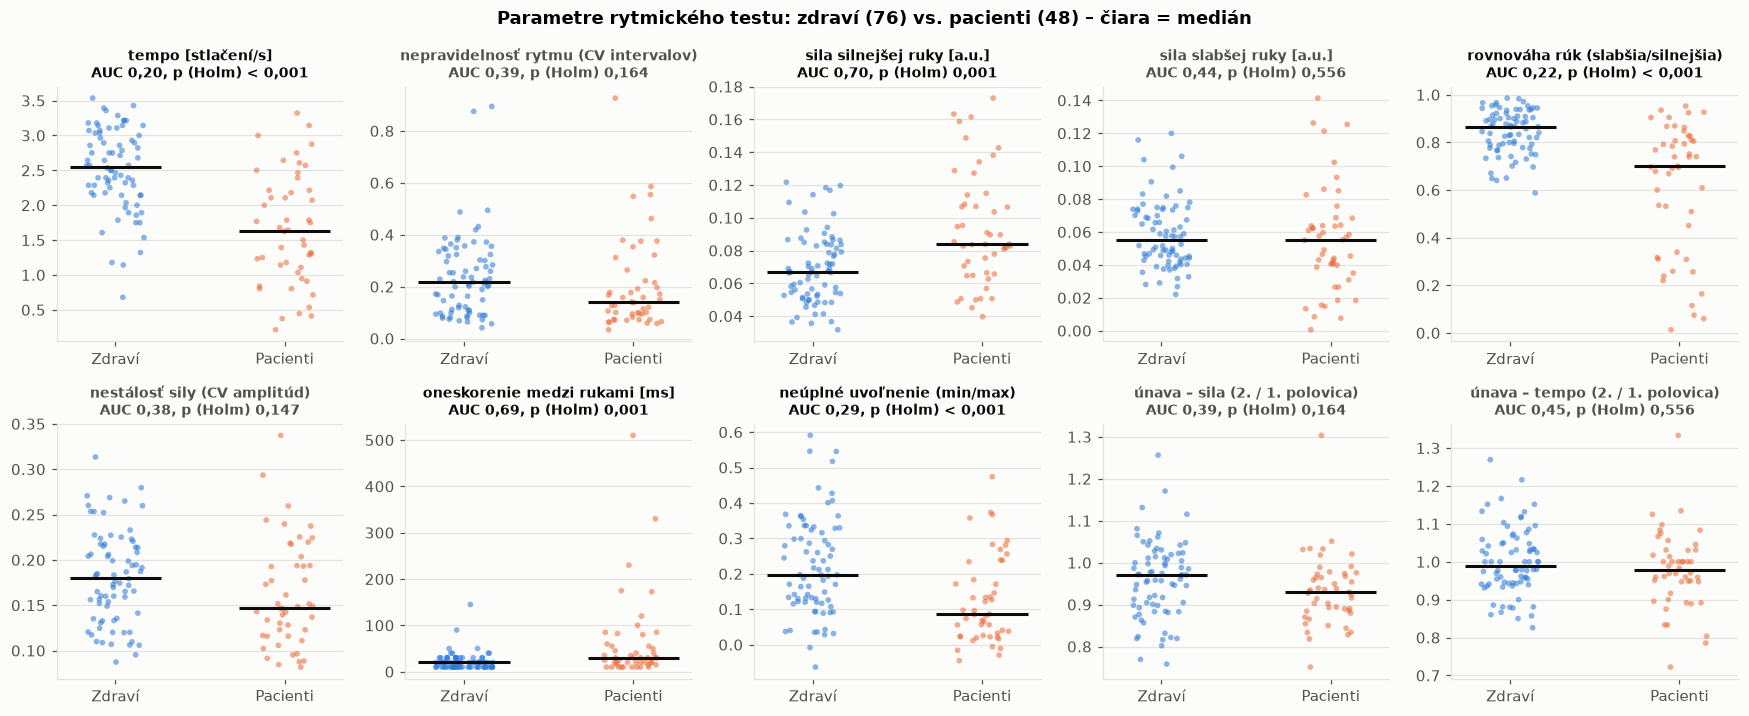

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
rng = np.random.default_rng(0)
for ax, parameter in zip(axes.flat, rp.PARAMETERS):
    for i, group in enumerate(GROUPS):
        v = main.loc[main["group"] == group, parameter].dropna()
        ax.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=14, color=GROUP_COLORS[group], alpha=0.55, edgecolor="none")
        ax.hlines(v.median(), i - 0.27, i + 0.27, color=TEXT, lw=2)
    p = h.loc[parameter, "p_holm"]
    ax.set_title(f"{NAME[parameter]}\nAUC {fmt(h.loc[parameter, 'auc'])}, p (Holm) {pval(p)}", fontsize=9,
                 color=TEXT if p < 0.05 else MUTED)
    ax.set_xticks([0, 1], [SK_GROUP[g] for g in GROUPS]); ax.grid(axis="x", visible=False)
fig.suptitle("Parametre rytmického testu: zdraví (76) vs. pacienti (48) – čiara = medián", fontweight="bold")
save(fig, "01_parametre_zdravi_vs_pacienti")

In [4]:
sig = h.loc[h["p_holm"] < 0.05]
sig50 = h.loc[h["p_50_holm"] < 0.05]
sig_age = h.loc[h["disease_p_holm"] < 0.05]
sig_tempo = h.loc[h["disease_tempo_p_holm"] < 0.05]
names = lambda frame: ", ".join(NAME[p].split(" [")[0].split(" (")[0] for p in frame.index) or "žiadny"
display(Markdown(f'''
**Záver 1:**
- **H0 zamietame** (Holm p < 0,05, všetci) pre **{len(sig)} z 10 parametrov**: {names(sig)}.
- **Pri porovnaní rovnako starých** (≥ 50 rokov) zostávajú významné: {names(sig50)}; v lineárnom modeli s vekom:
  {names(sig_age)}.
- **Najsilnejšie a najstabilnejšie rozdiely:** **rovnováha rúk** (pacienti ~0,70 vs. ~0,87) a **tempo**
  (~1,6 vs. ~2,6 stlačenia za sekundu).
- Dva rozdiely majú **opačný smer, ako sme čakali**: pacienti stláčajú silnejšou rukou **silnejšie** a ruky **úplnejšie
  uvoľňujú**. Súvisí to s pomalším tempom – kto stláča pomaly, stihne ruku úplne uvoľniť a stlačiť ju silnejšie.
  Ak do modelu pridáme tempo, zostáva významné: {names(sig_tempo)} (uvoľnenie už nie, je teda len dôsledkom tempa).
'''))


**Záver 1:**
- **H0 zamietame** (Holm p < 0,05, všetci) pre **5 z 10 parametrov**: tempo, sila silnejšej ruky, rovnováha rúk, oneskorenie medzi rukami, neúplné uvoľnenie.
- **Pri porovnaní rovnako starých** (≥ 50 rokov) zostávajú významné: rovnováha rúk, oneskorenie medzi rukami; v lineárnom modeli s vekom:
  tempo, sila silnejšej ruky, rovnováha rúk.
- **Najsilnejšie a najstabilnejšie rozdiely:** **rovnováha rúk** (pacienti ~0,70 vs. ~0,87) a **tempo**
  (~1,6 vs. ~2,6 stlačenia za sekundu).
- Dva rozdiely majú **opačný smer, ako sme čakali**: pacienti stláčajú silnejšou rukou **silnejšie** a ruky **úplnejšie
  uvoľňujú**. Súvisí to s pomalším tempom – kto stláča pomaly, stihne ruku úplne uvoľniť a stlačiť ju silnejšie.
  Ak do modelu pridáme tempo, zostáva významné: sila silnejšej ruky, rovnováha rúk (uvoľnenie už nie, je teda len dôsledkom tempa).


## 2. Zmeny parametrov s vekom u zdravých a „normálne" hodnoty podľa dekád

**a) Mení sa parameter s vekom?** Iba zdraví (76): Spearmanova korelácia s vekom a lineárna zmena za 10 rokov.

,parameter,Spearmanovo ρ,p,p (Holm),zmena za 10 rokov,95 % IS,závisí od veku
0,tempo [stlačení/s],-0.14,"0,232","1,000","-0,0731","[-0,1663; 0,0201]",nie
1,nepravidelnosť rytmu (CV intervalov),-0.08,"0,481","1,000","0,0023","[-0,0273; 0,0320]",nie
2,sila silnejšej ruky [a.u.],-0.02,"0,876","1,000","-0,0008","[-0,0036; 0,0019]",nie
3,sila slabšej ruky [a.u.],-0.01,"0,957","1,000","-0,0009","[-0,0036; 0,0017]",nie
4,rovnováha rúk (slabšia/silnejšia),0.07,"0,536","1,000","-0,0023","[-0,0154; 0,0108]",nie
5,nestálosť sily (CV amplitúd),-0.26,"0,024","0,188","-0,0052","[-0,0131; 0,0028]",nie
6,oneskorenie medzi rukami [ms],-0.30,"0,009","0,091","-1,1180","[-4,3007; 2,0647]",nie
7,neúplné uvoľnenie (min/max),-0.29,"0,010","0,091","-0,0175","[-0,0327; -0,0023]",nie
8,únava – sila (2. / 1. polovica),-0.08,"0,507","1,000","-0,0063","[-0,0167; 0,0041]",nie
9,únava – tempo (2. / 1. polovica),-0.19,"0,093","0,650","-0,0078","[-0,0176; 0,0020]",nie


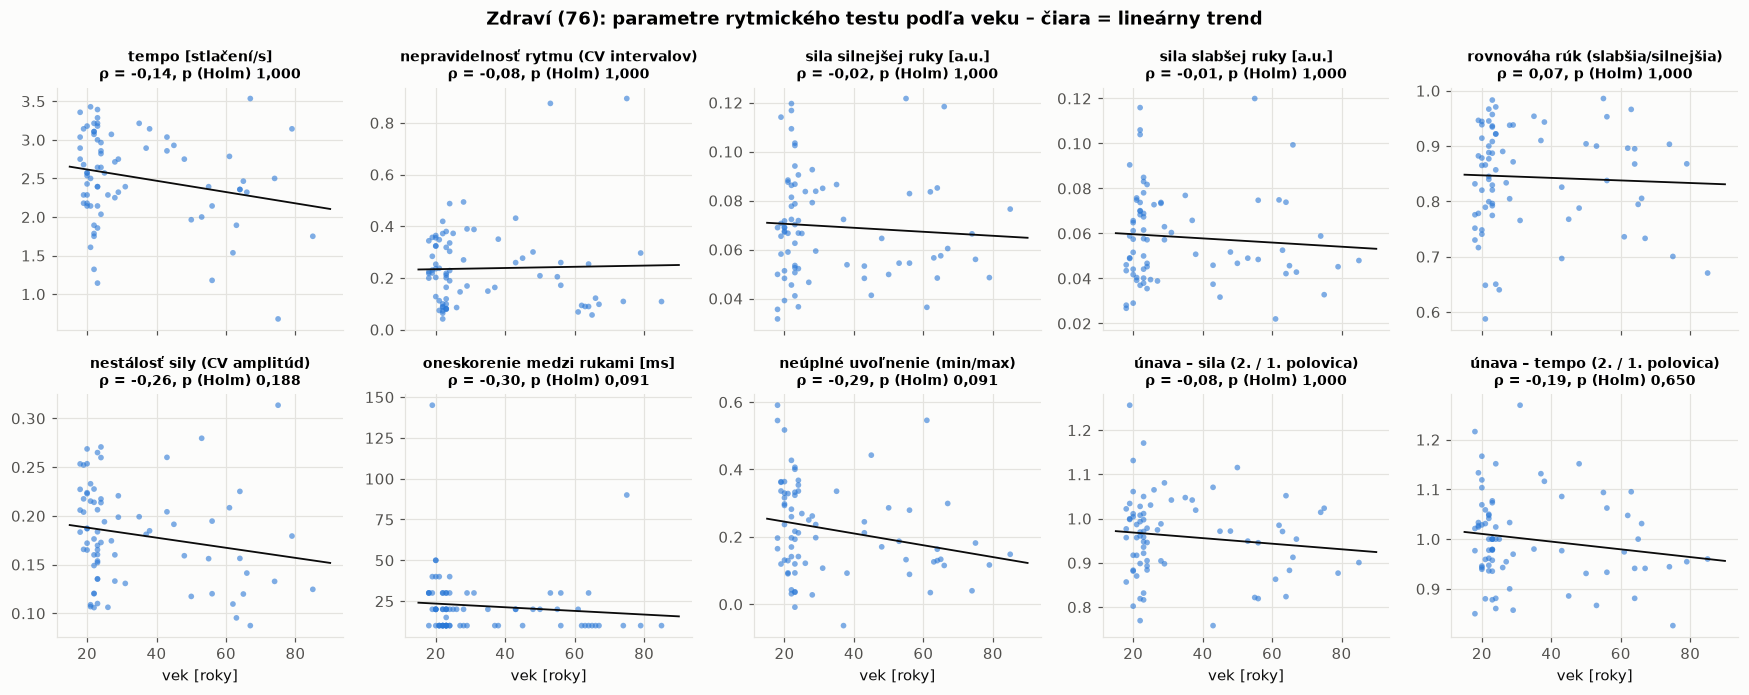

In [5]:
tr = T["age_trends"].set_index("parameter")
display(pd.DataFrame({
    "parameter": [NAME[p] for p in tr.index],
    "Spearmanovo ρ": tr["spearman_rho"].round(2).values, "p": tr["spearman_p"].map(pval).values,
    "p (Holm)": tr["spearman_p_holm"].map(pval).values,
    "zmena za 10 rokov": tr["change_per_10y"].map(lambda v: fmt(v, 4)).values,
    "95 % IS": ("[" + tr["change_ci_low"].map(lambda v: fmt(v, 4)) + "; " + tr["change_ci_high"].map(lambda v: fmt(v, 4)) + "]").values,
    "závisí od veku": np.where(tr["age_dependent"], "áno", "nie")}))

fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True)
for ax, parameter in zip(axes.flat, rp.PARAMETERS):
    ax.scatter(healthy["age"], healthy[parameter], s=14, color=GROUP_COLORS["control"], alpha=0.6, edgecolor="none")
    fit = np.polyfit(healthy["age"], healthy[parameter], 1)
    x = np.array([15, 90]); ax.plot(x, np.polyval(fit, x), color=TEXT, lw=1.2)
    ax.set_title(f"{NAME[parameter]}\nρ = {fmt(tr.loc[parameter, 'spearman_rho'])}, p (Holm) {pval(tr.loc[parameter, 'spearman_p_holm'])}",
                 fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("vek [roky]")
fig.suptitle("Zdraví (76): parametre rytmického testu podľa veku – čiara = lineárny trend", fontweight="bold")
save(fig, "02_zdravi_vek")

In [6]:
n_dep = int(tr["age_dependent"].sum())
nominal = tr.loc[(tr["spearman_p"] < 0.05) & ~tr["age_dependent"]]
display(Markdown(f'''
Po Holmovej korekcii **{"nezávisí od veku žiadny parameter" if n_dep == 0 else f"závisí od veku {n_dep} parametrov"}**.
Bez korekcie (p < 0,05) mierne klesá s vekom: {", ".join(NAME[p] for p in nominal.index) or "nič"} – sú to slabé
trendy (|ρ| ≤ 0,3), ktoré môžu byť aj náhodné alebo rozdielom medzi obdobiami merania (mladí TUKE 2025 vs. starší 9. 9. 2026).
'''))


Po Holmovej korekcii **nezávisí od veku žiadny parameter**.
Bez korekcie (p < 0,05) mierne klesá s vekom: nestálosť sily (CV amplitúd), oneskorenie medzi rukami [ms], neúplné uvoľnenie (min/max) – sú to slabé
trendy (|ρ| ≤ 0,3), ktoré môžu byť aj náhodné alebo rozdielom medzi obdobiami merania (mladí TUKE 2025 vs. starší 9. 9. 2026).


**b) Normálne hodnoty podľa dekád.** Počet zdravých v dekádach je veľmi nerovnomerný:

In [7]:
counts = healthy["decade"].value_counts(sort=False)
display(counts.rename("zdravých").to_frame().T)

decade,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
zdravých,8,43,4,4,5,8,3,1


Spoľahlivý empirický rozsah (2,5. – 97,5. percentil) potrebuje aspoň ~20 osôb (klinické odporúčanie je až 120) – to má
iba dekáda **20–29 rokov** (43 osôb). V ostatných dekádach sú 1–8 osoby, z ktorých sa normálny rozsah určiť nedá.

Preto normu počítame **zo všetkých zdravých naraz**:
- parameter **bez vplyvu veku** → rovnaký rozsah pre všetky dekády (2,5. – 97,5. percentil všetkých 76 zdravých);
- parameter **s vplyvom veku** → kvantilová regresia na vek (medián a hranice sa menia lineárne s vekom),
  hodnota v strede dekády.

Hodnota pacienta **mimo rozsahu** = horšia ako u 97,5 % zdravých jeho veku.

In [8]:
model_norms = T["norms_by_age_model"]
emp = T["decade_norms"]
rows = []
for parameter in rp.PARAMETERS:
    m = model_norms.loc[model_norms["parameter"] == parameter].set_index("decade")
    e = emp.loc[emp["parameter"] == parameter].set_index("decade")
    row = {"parameter": NAME[parameter], "metóda": m["method"].iloc[0]}
    for decade in AGE_CATEGORY_LABELS:
        row[decade] = f"{fmt(m.loc[decade, 'q50'], 3)} [{fmt(m.loc[decade, 'q2.5'], 3)}–{fmt(m.loc[decade, 'q97.5'], 3)}]"
    rows.append(row)
print("Normálne hodnoty: medián [2,5. – 97,5. percentil] pre každú dekádu (zo všetkých 76 zdravých):")
display(pd.DataFrame(rows).set_index("parameter"))

e = emp.copy()
e["empiricky"] = np.where(e["reliable"], e["median"].map(lambda v: fmt(v, 3)) + " [" + e["p2_5"].map(lambda v: fmt(v, 3))
                          + "–" + e["p97_5"].map(lambda v: fmt(v, 3)) + "]",
                          np.where(e["n"] > 0, e["median"].map(lambda v: fmt(v, 3)) + " (n=" + e["n"].astype(str) + ", málo)", "–"))
print("Kontrola – empiricky v každej dekáde zvlášť (rozsah len pri n ≥ 20, inak iba medián):")
display(e.pivot(index="parameter", columns="decade", values="empiricky").reindex(index=rp.PARAMETERS, columns=AGE_CATEGORY_LABELS)
        .rename(index=NAME))

Normálne hodnoty: medián [2,5. – 97,5. percentil] pre každú dekádu (zo všetkých 76 zdravých):


,metóda,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
parameter,,,,,,,,,
tempo [stlačení/s],spoločná norma (bez vplyvu veku),"2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]","2,554 [1,174–3,397]"
nepravidelnosť rytmu (CV intervalov),spoločná norma (bez vplyvu veku),"0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]","0,217 [0,063–0,542]"
sila silnejšej ruky [a.u.],spoločná norma (bez vplyvu veku),"0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]","0,067 [0,036–0,119]"
sila slabšej ruky [a.u.],spoločná norma (bez vplyvu veku),"0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]","0,055 [0,028–0,107]"
rovnováha rúk (slabšia/silnejšia),spoločná norma (bez vplyvu veku),"0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]","0,865 [0,647–0,972]"
nestálosť sily (CV amplitúd),spoločná norma (bez vplyvu veku),"0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]","0,180 [0,105–0,272]"
oneskorenie medzi rukami [ms],spoločná norma (bez vplyvu veku),"20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]","20,000 [10,000–55,000]"
neúplné uvoľnenie (min/max),spoločná norma (bez vplyvu veku),"0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]","0,197 [0,023–0,545]"
únava – sila (2. / 1. polovica),spoločná norma (bez vplyvu veku),"0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]","0,970 [0,798–1,136]"


Kontrola – empiricky v každej dekáde zvlášť (rozsah len pri n ≥ 20, inak iba medián):


decade,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
parameter,,,,,,,,
tempo [stlačení/s],"2,821 (n=8, málo)","2,571 [1,336–3,387]","3,018 (n=4, málo)","2,893 (n=4, málo)","2,000 (n=5, málo)","2,357 (n=8, málo)","2,500 (n=3, málo)","1,750 (n=1, málo)"
nepravidelnosť rytmu (CV intervalov),"0,227 (n=8, málo)","0,211 [0,064–0,484]","0,257 (n=4, málo)","0,288 (n=4, málo)","0,208 (n=5, málo)","0,092 (n=8, málo)","0,296 (n=3, málo)","0,109 (n=1, málo)"
sila silnejšej ruky [a.u.],"0,062 (n=8, málo)","0,070 [0,039–0,116]","0,079 (n=4, málo)","0,051 (n=4, málo)","0,054 (n=5, málo)","0,059 (n=8, málo)","0,056 (n=3, málo)","0,077 (n=1, málo)"
sila slabšej ruky [a.u.],"0,047 (n=8, málo)","0,062 [0,036–0,106]","0,063 (n=4, málo)","0,042 (n=4, málo)","0,049 (n=5, málo)","0,049 (n=8, málo)","0,045 (n=3, málo)","0,048 (n=1, málo)"
rovnováha rúk (slabšia/silnejšia),"0,777 (n=8, málo)","0,871 [0,641–0,970]","0,927 (n=4, málo)","0,778 (n=4, málo)","0,904 (n=5, málo)","0,836 (n=8, málo)","0,868 (n=3, málo)","0,670 (n=1, málo)"
nestálosť sily (CV amplitúd),"0,212 (n=8, málo)","0,174 [0,106–0,268]","0,183 (n=4, málo)","0,198 (n=4, málo)","0,156 (n=5, málo)","0,131 (n=8, málo)","0,179 (n=3, málo)","0,125 (n=1, málo)"
oneskorenie medzi rukami [ms],"30,000 (n=8, málo)","20,000 [10,000–49,500]","15,000 (n=4, málo)","20,000 (n=4, málo)","20,000 (n=5, málo)","10,000 (n=8, málo)","10,000 (n=3, málo)","10,000 (n=1, málo)"
neúplné uvoľnenie (min/max),"0,349 (n=8, málo)","0,237 [0,028–0,426]","0,100 (n=4, málo)","0,228 (n=4, málo)","0,187 (n=5, málo)","0,132 (n=8, málo)","0,117 (n=3, málo)","0,148 (n=1, málo)"
únava – sila (2. / 1. polovica),"0,999 (n=8, málo)","0,958 [0,803–1,129]","1,042 (n=4, málo)","0,972 (n=4, málo)","0,945 (n=5, málo)","0,933 (n=8, málo)","1,014 (n=3, málo)","0,901 (n=1, málo)"


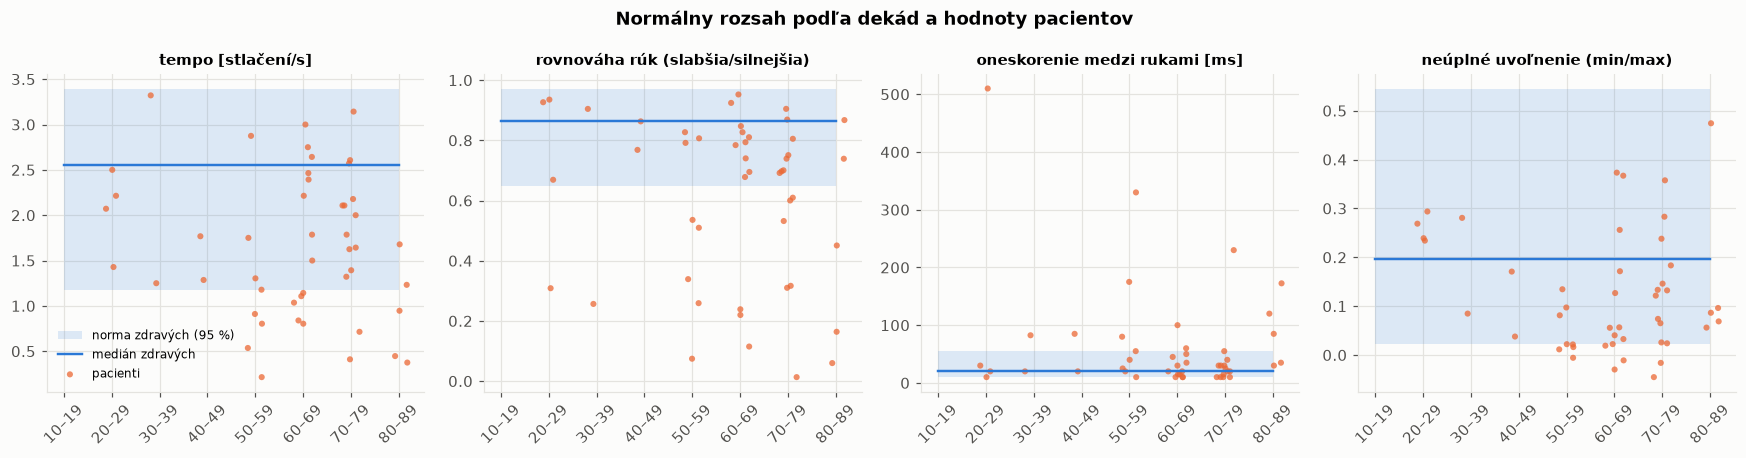

Koľko pacientov je mimo normálneho rozsahu svojej dekády:


,pod normou,nad normou,pacientov
tempo [stlačení/s],14,0,48
nepravidelnosť rytmu (CV intervalov),4,4,48
sila silnejšej ruky [a.u.],0,10,48
sila slabšej ruky [a.u.],10,4,48
rovnováha rúk (slabšia/silnejšia),19,0,48
nestálosť sily (CV amplitúd),8,2,48
oneskorenie medzi rukami [ms],0,12,48
neúplné uvoľnenie (min/max),11,0,48
únava – sila (2. / 1. polovica),1,1,48
únava – tempo (2. / 1. polovica),5,1,48


In [9]:
KEY = ["press_rate_hz", "balance", "sync_lag_ms", "release_ratio"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
x = np.arange(len(AGE_CATEGORY_LABELS))
for ax, parameter in zip(axes, KEY):
    m = model_norms.loc[model_norms["parameter"] == parameter].set_index("decade").reindex(AGE_CATEGORY_LABELS)
    ax.fill_between(x, m["q2.5"], m["q97.5"], color=GROUP_COLORS["control"], alpha=0.15, lw=0, label="norma zdravých (95 %)")
    ax.plot(x, m["q50"], color=GROUP_COLORS["control"], lw=1.6, label="medián zdravých")
    pts = main.loc[main["group"] == "patient"]
    pos = pts["decade"].cat.codes.to_numpy() + np.random.default_rng(1).uniform(-0.2, 0.2, len(pts))
    ax.scatter(pos, pts[parameter], s=16, color=GROUP_COLORS["patient"], alpha=0.75, edgecolor="none", label="pacienti")
    ax.set_xticks(x, AGE_CATEGORY_LABELS, rotation=45); ax.set_title(NAME[parameter], fontsize=9.5)
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Normálny rozsah podľa dekád a hodnoty pacientov", fontweight="bold")
save(fig, "03_normy_podla_dekad")

outside = {}
for parameter in rp.PARAMETERS:
    m = model_norms.loc[model_norms["parameter"] == parameter].set_index("decade")
    pts = main.loc[main["group"] == "patient"].dropna(subset=[parameter])
    low = pts["decade"].map(m["q2.5"]).astype(float); high = pts["decade"].map(m["q97.5"]).astype(float)
    outside[NAME[parameter]] = {"pod normou": int((pts[parameter] < low).sum()), "nad normou": int((pts[parameter] > high).sum()),
                                "pacientov": len(pts)}
print("Koľko pacientov je mimo normálneho rozsahu svojej dekády:")
display(pd.DataFrame(outside).T)

## 3. Klasifikátor: zdravý vs. pacient

**Modely:**
- **logistická regresia** (hlavný model – jednoduchý a dá sa vysvetliť; parametre sú štandardizované, triedy vyvážené),
- **náhodný les** (random forest, 300 stromov – zachytí aj nelineárne vzťahy).

**Hodnotenie:** dát je málo (124 osôb), preto **opakovaná 5-násobná krížová validácia** (20 opakovaní): model sa vždy učí
na 4/5 osôb a hodnotí na zvyšnej 1/5, ktorú nevidel. Uvádzame priemer a 95 % rozsah cez opakovania:
- **AUC** – schopnosť oddeliť skupiny (0,5 = náhoda, 1 = dokonalé oddelenie),
- **citlivosť** – podiel správne rozpoznaných pacientov, **špecificita** – podiel správne rozpoznaných zdravých (prah 0,5).

**Pozor na vek:** pacienti sú oveľa starší. Preto porovnávame aj klasifikátor **len podľa veku** a klasifikátor
**len na osobách ≥ 50 rokov**, kde vek skupiny takmer neodlišuje.

In [10]:
clf = T["classifier"]
mainclf = clf.loc[clf["set"].str.startswith("76")]
show = lambda frame: pd.DataFrame({
    "množina": frame["set"], "príznaky": frame["features"], "model": frame["model"], "osôb": frame["n_people"],
    "AUC": frame["auc"].map(fmt) + " [" + frame["auc_low"].map(fmt) + "–" + frame["auc_high"].map(fmt) + "]",
    "citlivosť": frame["sensitivity"].map(fmt), "špecificita": frame["specificity"].map(fmt),
    "vyvážená presnosť": frame["balanced_accuracy"].map(fmt)}).reset_index(drop=True)
display(show(mainclf))
perm = T["permutation_test"].iloc[0]
print(f"Permutačný test (logistická regresia, parametre rytmu): AUC {fmt(perm['auc'])}, s náhodne pomiešanými skupinami "
      f"priemer {fmt(perm['null_mean'])} (97,5 % {fmt(perm['null_p97_5'])}), p = {pval(perm['p'])}")

,množina,príznaky,model,osôb,AUC,citlivosť,špecificita,vyvážená presnosť
0,76 zdravých + 48 pacientov,parametre rytmu,logistická regresia,124,"0,85 [0,83–0,87]","0,76","0,83","0,79"
1,76 zdravých + 48 pacientov,parametre rytmu + vek,logistická regresia,124,"0,90 [0,89–0,92]","0,85","0,87","0,86"
2,76 zdravých + 48 pacientov,len vek,logistická regresia,124,"0,84 [0,83–0,85]","0,85","0,77","0,81"
3,76 zdravých + 48 pacientov,parametre rytmu,náhodný les,124,"0,82 [0,80–0,85]","0,70","0,85","0,78"
4,76 zdravých + 48 pacientov,parametre rytmu + vek,náhodný les,124,"0,89 [0,87–0,90]","0,79","0,85","0,82"
5,76 zdravých + 48 pacientov,len vek,náhodný les,124,"0,80 [0,77–0,82]","0,78","0,76","0,77"
6,"76 zdravých + 48 pacientov, len ≥ 50 rokov",parametre rytmu,logistická regresia,57,"0,80 [0,73–0,85]","0,76","0,71","0,73"
7,"76 zdravých + 48 pacientov, len ≥ 50 rokov",parametre rytmu,náhodný les,57,"0,73 [0,67–0,78]","0,72","0,58","0,65"


Permutačný test (logistická regresia, parametre rytmu): AUC 0,85, s náhodne pomiešanými skupinami priemer 0,49 (97,5 % 0,62), p = 0,005


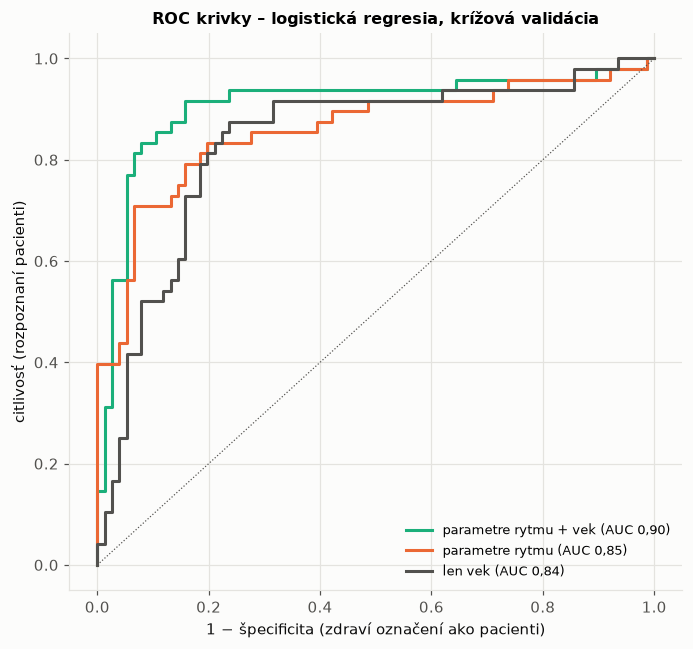

In [11]:
from sklearn.metrics import roc_curve
oof = T["classifier_oof"]
fig, ax = plt.subplots(figsize=(6.4, 6))
styles = [("logistická regresia | parametre rytmu + vek", "#1baf7a", "parametre rytmu + vek"),
          ("logistická regresia | parametre rytmu", GROUP_COLORS["patient"], "parametre rytmu"),
          ("logistická regresia | len vek", MUTED, "len vek")]
for column, color, label in styles:
    fpr, tpr, _ = roc_curve(oof["patient"], oof[column])
    auc = mainclf.loc[(mainclf["model"] == "logistická regresia") & (mainclf["features"] == label), "auc"].iloc[0]
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {fmt(auc)})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("1 − špecificita (zdraví označení ako pacienti)"); ax.set_ylabel("citlivosť (rozpoznaní pacienti)")
ax.set_title("ROC krivky – logistická regresia, krížová validácia"); ax.legend(loc="lower right", fontsize=8.5)
save(fig, "04_roc")

In [12]:
get = lambda feat, model="logistická regresia", s="76 zdravých + 48 pacientov": clf.loc[
    (clf["set"] == s) & (clf["features"] == feat) & (clf["model"] == model)].iloc[0]
p_lr, pa_lr, a_lr = get("parametre rytmu"), get("parametre rytmu + vek"), get("len vek")
o_lr = get("parametre rytmu", s="76 zdravých + 48 pacientov, len ≥ 50 rokov")
rf = get("parametre rytmu", "náhodný les")
display(Markdown(f'''
**Záver 3:**
- Logistická regresia z 10 parametrov rytmu oddelí pacientov so **AUC {fmt(p_lr["auc"])}** (citlivosť {fmt(p_lr["sensitivity"])},
  špecificita {fmt(p_lr["specificity"])}); výrazne lepšie ako náhoda (permutačný test p {pval(perm["p"])}). Náhodný les nie je
  lepší (AUC {fmt(rf["auc"])}), preto ako hlavný model ostáva jednoduchšia logistická regresia.
- **Samotný vek** však dosahuje AUC {fmt(a_lr["auc"])} – v týchto dátach je vek takmer rovnako silný „príznak" ako rytmus,
  lebo pacienti sú starší. Vek a rytmus spolu dávajú AUC {fmt(pa_lr["auc"])}, čiže **rytmus pridáva informáciu navyše
  k veku**.
- **Rovnako starí (≥ 50 rokov, 17 zdravých a 40 pacientov):** parametre rytmu stále oddeľujú skupiny s AUC
  {fmt(o_lr["auc"])} [{fmt(o_lr["auc_low"])}–{fmt(o_lr["auc_high"])}] – rozdiel teda nie je len vekom. Výsledok je však menej
  istý (málo starších zdravých).
'''))


**Záver 3:**
- Logistická regresia z 10 parametrov rytmu oddelí pacientov so **AUC 0,85** (citlivosť 0,76,
  špecificita 0,83); výrazne lepšie ako náhoda (permutačný test p 0,005). Náhodný les nie je
  lepší (AUC 0,82), preto ako hlavný model ostáva jednoduchšia logistická regresia.
- **Samotný vek** však dosahuje AUC 0,84 – v týchto dátach je vek takmer rovnako silný „príznak" ako rytmus,
  lebo pacienti sú starší. Vek a rytmus spolu dávajú AUC 0,90, čiže **rytmus pridáva informáciu navyše
  k veku**.
- **Rovnako starí (≥ 50 rokov, 17 zdravých a 40 pacientov):** parametre rytmu stále oddeľujú skupiny s AUC
  0,80 [0,73–0,85] – rozdiel teda nie je len vekom. Výsledok je však menej
  istý (málo starších zdravých).


## 4. Ablačná analýza – vplyv jednotlivých faktorov

Pre každú skupinu parametrov (faktor) dvakrát zopakujeme krížovú validáciu logistickej regresie:
- **bez faktora** – model dostane všetky ostatné parametre; pokles AUC = čo stratíme, keď faktor vynecháme,
- **iba faktor** – model dostane len tento faktor; AUC = koľko dokáže faktor sám.

Robíme to dvakrát: (A) iba parametre rytmu, (B) parametre rytmu + vek ako ďalší faktor.

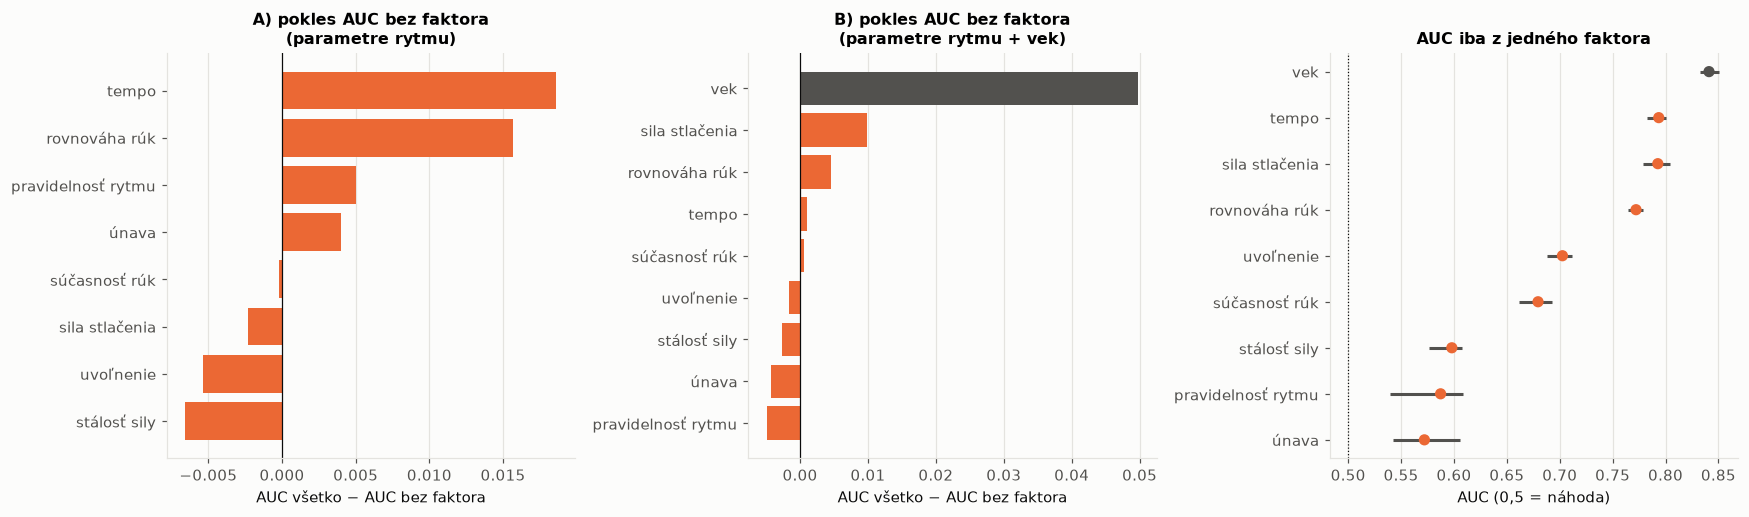

,parametre,AUC bez faktora,pokles AUC,AUC iba faktor
faktor,,,,
tempo,press_rate_hz,0.833,0.019,0.794
rovnováha rúk,balance,0.836,0.016,0.772
pravidelnosť rytmu,interval_cv,0.846,0.005,0.587
únava,"fatigue_amplitude, fatigue_rate",0.847,0.004,0.572
súčasnosť rúk,sync_lag_ms,0.852,-0.000,0.679
sila stlačenia,"amplitude_strong, amplitude_weak",0.854,-0.002,0.793
uvoľnenie,release_ratio,0.857,-0.005,0.703
stálosť sily,amplitude_cv,0.858,-0.007,0.598


In [13]:
abl = T["ablation_parameters"]; abl_age = T["ablation_with_age"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, frame, title in [(axes[0], abl, "A) pokles AUC bez faktora\n(parametre rytmu)"),
                         (axes[1], abl_age, "B) pokles AUC bez faktora\n(parametre rytmu + vek)")]:
    frame = frame.sort_values("auc_drop")
    colors = [MUTED if g == "vek" else GROUP_COLORS["patient"] for g in frame["group"]]
    ax.barh(frame["group"], frame["auc_drop"], color=colors)
    ax.axvline(0, color=TEXT, lw=0.8); ax.set_title(title); ax.set_xlabel("AUC všetko − AUC bez faktora")
    ax.grid(axis="y", visible=False)
alone = abl_age.sort_values("auc_alone")
axes[2].hlines(range(len(alone)), alone["auc_alone_low"], alone["auc_alone_high"], color=MUTED, lw=2)
axes[2].scatter(alone["auc_alone"], range(len(alone)), color=[MUTED if g == "vek" else GROUP_COLORS["patient"] for g in alone["group"]],
                s=40, zorder=3)
axes[2].set_yticks(range(len(alone)), alone["group"]); axes[2].axvline(0.5, color=TEXT, lw=0.8, ls=":")
axes[2].set_title("AUC iba z jedného faktora"); axes[2].set_xlabel("AUC (0,5 = náhoda)"); axes[2].grid(axis="y", visible=False)
save(fig, "05_ablacia")
display(pd.DataFrame({"faktor": abl["group"], "parametre": abl["features"], "AUC bez faktora": abl["auc_without"].round(3),
                      "pokles AUC": abl["auc_drop"].round(3), "AUC iba faktor": abl["auc_alone"].round(3)}).set_index("faktor"))

In [14]:
top_alone = abl.sort_values("auc_alone", ascending=False).head(3)
age_row = abl_age.set_index("group").loc["vek"]
top_drop = abl.iloc[0]
display(Markdown(f'''
**Záver 4:**
- **Samy osebe** oddeľujú skupiny najlepšie: {", ".join(f"{r.group} (AUC {fmt(r.auc_alone)})" for r in top_alone.itertuples())}.
  Pravidelnosť rytmu, stálosť sily a únava samy takmer nepomáhajú (AUC ~0,57–0,60).
- **Po vynechaní** jedného faktora AUC klesne najviac pri faktore **{top_drop["group"]}** (o {fmt(top_drop["auc_drop"], 3)}).
  Poklesy sú malé, lebo parametre sa **navzájom zastupujú** – napr. tempo súvisí so silou, uvoľnením aj oneskorením rúk,
  takže keď jeden chýba, model použije ostatné.
- **Rovnováha rúk** je silný faktor, ktorý od tempa nezávisí (rozdiel zostáva aj pri rovnakom tempe aj veku) – nesie
  informáciu, ktorú ostatné parametre nemajú.
- Ak je v modeli aj **vek**, je to faktor s najväčším poklesom AUC (o {fmt(age_row["auc_drop"], 3)}) – opäť ukazuje, že
  vek je v týchto dátach silne zviazaný so skupinou.
'''))


**Záver 4:**
- **Samy osebe** oddeľujú skupiny najlepšie: tempo (AUC 0,79), sila stlačenia (AUC 0,79), rovnováha rúk (AUC 0,77).
  Pravidelnosť rytmu, stálosť sily a únava samy takmer nepomáhajú (AUC ~0,57–0,60).
- **Po vynechaní** jedného faktora AUC klesne najviac pri faktore **tempo** (o 0,019).
  Poklesy sú malé, lebo parametre sa **navzájom zastupujú** – napr. tempo súvisí so silou, uvoľnením aj oneskorením rúk,
  takže keď jeden chýba, model použije ostatné.
- **Rovnováha rúk** je silný faktor, ktorý od tempa nezávisí (rozdiel zostáva aj pri rovnakom tempe aj veku) – nesie
  informáciu, ktorú ostatné parametre nemajú.
- Ak je v modeli aj **vek**, je to faktor s najväčším poklesom AUC (o 0,050) – opäť ukazuje, že
  vek je v týchto dátach silne zviazaný so skupinou.


## 5. Kontroly
1. **Všetci zdraví (90)** namiesto 76 bez ťažkostí.
2. **S 1. pokusom** (všetky 4 pokusy).

In [15]:
checks = clf.loc[~clf["set"].str.startswith("76") & (clf["model"] == "logistická regresia")]
display(show(checks))
h90 = T["hypotheses_all_90_healthy"].set_index("parameter"); h1 = T["hypotheses_with_first_attempt"].set_index("parameter")
display(pd.DataFrame({"hlavná analýza (76, pokusy 2–4)": h["p_holm"].map(pval),
                      "90 zdravých": h90["p_holm"].map(pval), "s 1. pokusom": h1["p_holm"].map(pval),
                      "AUC hlavná": h["auc"].round(2), "AUC 90 zdravých": h90["auc"].round(2), "AUC s 1. pokusom": h1["auc"].round(2)})
        .rename(index=NAME).rename_axis("Mann-Whitney p (Holm) a AUC"))

,množina,príznaky,model,osôb,AUC,citlivosť,špecificita,vyvážená presnosť
0,90 zdravých + 48 pacientov,parametre rytmu,logistická regresia,138,"0,84 [0,83–0,86]","0,75","0,82","0,79"
1,90 zdravých + 48 pacientov,parametre rytmu + vek,logistická regresia,138,"0,89 [0,88–0,90]","0,85","0,86","0,85"
2,90 zdravých + 48 pacientov,len vek,logistická regresia,138,"0,82 [0,81–0,82]","0,84","0,73","0,78"
3,"90 zdravých + 48 pacientov, len ≥ 50 rokov",parametre rytmu,logistická regresia,64,"0,80 [0,75–0,85]","0,76","0,75","0,75"
4,s 1. pokusom,parametre rytmu,logistická regresia,124,"0,86 [0,84–0,87]","0,77","0,81","0,79"
5,s 1. pokusom,parametre rytmu + vek,logistická regresia,124,"0,90 [0,89–0,92]","0,85","0,88","0,87"
6,s 1. pokusom,len vek,logistická regresia,124,"0,84 [0,83–0,85]","0,85","0,77","0,81"
7,"s 1. pokusom, len ≥ 50 rokov",parametre rytmu,logistická regresia,57,"0,81 [0,74–0,85]","0,77","0,71","0,74"


,"hlavná analýza (76, pokusy 2–4)",90 zdravých,s 1. pokusom,AUC hlavná,AUC 90 zdravých,AUC s 1. pokusom
Mann-Whitney p (Holm) a AUC,,,,,,
tempo [stlačení/s],"< 0,001","< 0,001","< 0,001",0.20,0.21,0.20
nepravidelnosť rytmu (CV intervalov),"0,164","0,155","0,108",0.39,0.40,0.38
sila silnejšej ruky [a.u.],"0,001","< 0,001","< 0,001",0.70,0.71,0.71
sila slabšej ruky [a.u.],"0,556","0,582","0,297",0.44,0.46,0.43
rovnováha rúk (slabšia/silnejšia),"< 0,001","< 0,001","< 0,001",0.22,0.24,0.22
nestálosť sily (CV amplitúd),"0,147","0,099","0,255",0.38,0.38,0.40
oneskorenie medzi rukami [ms],"0,001","0,001","0,003",0.69,0.69,0.68
neúplné uvoľnenie (min/max),"< 0,001","< 0,001","< 0,001",0.29,0.29,0.28
únava – sila (2. / 1. polovica),"0,164","0,055","0,297",0.39,0.37,0.42


Výsledky testov aj klasifikátora sa pri oboch kontrolách menia len málo – závery nezávisia od výberu zdravých ani od
toho, či použijeme 1. pokus.

In [16]:
display(Markdown(f'''
## Zhrnutie

1. **Hypotézy:** pre {len(sig)} z 10 parametrov rytmického testu zamietame H0 – zdraví a pacienti sa líšia. Najsilnejšie
   a najstabilnejšie rozdiely sú v **rovnováhe rúk** a v **tempe**; rovnováha zostáva významná aj pri rovnakom veku
   a rovnakom tempe. Časť ďalších rozdielov je len dôsledkom pomalšieho tempa pacientov.
2. **Vek u zdravých:** po korekcii na viacnásobné testovanie {"sa s vekom nemení žiadny parameter" if n_dep == 0 else f"závisí od veku {n_dep} parametrov"};
   **normálne hodnoty** sú preto pre všetky dekády rovnaké (tabuľka v časti 2b). Empiricky v každej dekáde zvlášť sa dajú
   určiť len pre 20–29 rokov – v ostatných dekádach je zdravých príliš málo.
3. **Klasifikátor:** logistická regresia z parametrov rytmu – AUC {fmt(p_lr["auc"])}, s vekom {fmt(pa_lr["auc"])};
   samotný vek {fmt(a_lr["auc"])}; len ≥ 50 rokov {fmt(o_lr["auc"])}.
4. **Ablácia:** najviac prispievajú **tempo, rovnováha rúk a sila stlačenia**; parametre sa navzájom zastupujú.

**Obmedzenia:** zdraví a pacienti hrali inú verziu rytmickej hry (iné `step_id`) a pacienti sú výrazne starší – klasifikátor
preto čiastočne môže rozoznávať vek alebo verziu hry; zdravých nad 50 rokov je len 17 (bez ťažkostí), preto normy pre
staršie dekády stoja na predpoklade, že parameter sa s vekom nemení; klasifikátor nie je overený na nezávislých dátach.
'''))


## Zhrnutie

1. **Hypotézy:** pre 5 z 10 parametrov rytmického testu zamietame H0 – zdraví a pacienti sa líšia. Najsilnejšie
   a najstabilnejšie rozdiely sú v **rovnováhe rúk** a v **tempe**; rovnováha zostáva významná aj pri rovnakom veku
   a rovnakom tempe. Časť ďalších rozdielov je len dôsledkom pomalšieho tempa pacientov.
2. **Vek u zdravých:** po korekcii na viacnásobné testovanie sa s vekom nemení žiadny parameter;
   **normálne hodnoty** sú preto pre všetky dekády rovnaké (tabuľka v časti 2b). Empiricky v každej dekáde zvlášť sa dajú
   určiť len pre 20–29 rokov – v ostatných dekádach je zdravých príliš málo.
3. **Klasifikátor:** logistická regresia z parametrov rytmu – AUC 0,85, s vekom 0,90;
   samotný vek 0,84; len ≥ 50 rokov 0,80.
4. **Ablácia:** najviac prispievajú **tempo, rovnováha rúk a sila stlačenia**; parametre sa navzájom zastupujú.

**Obmedzenia:** zdraví a pacienti hrali inú verziu rytmickej hry (iné `step_id`) a pacienti sú výrazne starší – klasifikátor
preto čiastočne môže rozoznávať vek alebo verziu hry; zdravých nad 50 rokov je len 17 (bez ťažkostí), preto normy pre
staršie dekády stoja na predpoklade, že parameter sa s vekom nemení; klasifikátor nie je overený na nezávislých dátach.
